# Fase 2 · Modelos de la entrega 1: Adaline, SOM y red RBF

Objetivo: comparar un modelo lineal (Adaline entrenado con pseudoinversa) contra uno no lineal (red RBF) en la clasificación de latidos N / S / V con **evaluación inter-paciente**, y usar un mapa SOM para ver el traslape de las clases.

Protocolo, para no hacer trampa con el conjunto de prueba:
1. Los hiperparámetros se eligen **solo con DS1**, con validación cruzada dejando un paciente fuera a la vez.
2. Con la configuración elegida se entrena con todo DS1 y se evalúa **una sola vez** en DS2.

Requiere el archivo `mitbih_ds1_ds2.npz` que genera el cuaderno de la fase 0; si no está, la celda siguiente lo genera.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

NPZ = os.environ.get('NPZ', 'mitbih_ds1_ds2.npz')
if not os.path.exists(NPZ):
    # Genera los datos corriendo el cuaderno de la fase 0 (descarga MIT-BIH, ~3 min)
    !pip install -q wfdb
    !git clone -q https://github.com/juansaavedra0604-oss/arritmias-ecg
    %run arritmias-ecg/notebooks/fase0_mitbih.ipynb

d = np.load(NPZ)
X1, F1, y1, p1 = d['X1'], d['F1'], d['y1'], d['p1']
X2, F2, y2, p2 = d['X2'], d['F2'], d['y2'], d['p2']
CL = np.array(['N', 'S', 'V'])
print('DS1:', X1.shape, dict(zip(*np.unique(y1, return_counts=True))))
print('DS2:', X2.shape, dict(zip(*np.unique(y2, return_counts=True))))

DS1: (50555, 234) {np.str_('N'): np.int64(45824), np.str_('S'): np.int64(943), np.str_('V'): np.int64(3788)}
DS2: (49273, 234) {np.str_('N'): np.int64(44218), np.str_('S'): np.int64(1836), np.str_('V'): np.int64(3219)}


## 1. Entradas del modelo

**Normalización por paciente.** La amplitud del ECG y el ritmo cambian mucho entre personas. Para cada registro:
- se divide el latido entre la mediana de la amplitud de sus picos R;
- se agregan tres rasgos RR divididos entre el RR medio de ese registro.

Esto usa solo la señal del propio paciente, sin etiquetas, así que es válido también en DS2.

**Vector de entrada (85 valores):** el latido submuestreado a 120 Hz (78 muestras) + 7 rasgos RR, estandarizados con la media y la desviación del conjunto de entrenamiento. El factor `a_rr` multiplica los rasgos RR para que pesen más en las distancias de la RBF y el SOM; en el Adaline no cambia nada, porque un modelo lineal absorbe la escala.

In [2]:
def norm_paciente(X, F, p):
    Xn = X.astype(np.float64).copy()
    for q in np.unique(p):
        m = p == q
        Xn[m] /= np.median(np.abs(X[m, 90])) + 1e-8          # 90 = posición del pico R en la ventana
    rr_med = {q: F[p == q, 0].mean() for q in np.unique(p)}
    rm = np.array([rr_med[q] for q in p])
    Fn = np.column_stack([F, F[:, 0] / rm, F[:, 1] / rm, F[:, 2] / rm])
    return Xn, Fn

def entradas(X, F, ref=None, ds=3, a_rr=1.0):
    Z = np.hstack([X[:, ::ds], F]).astype(np.float64)
    if ref is None:
        ref = (Z.mean(0), Z.std(0) + 1e-8)                    # solo con datos de entrenamiento
    Z = (Z - ref[0]) / ref[1]
    Z[:, -F.shape[1]:] *= a_rr
    return Z, ref

X1n, F1n = norm_paciente(X1, F1, p1)
X2n, F2n = norm_paciente(X2, F2, p2)
print('Rasgos por latido:', entradas(X1n[:5], F1n[:5])[0].shape[1])

Rasgos por latido: 85


## 2. Métricas
Con 1,9 % de latidos S, la exactitud engaña: un modelo que diga siempre "N" acierta el 90 %. Se reporta por clase la **sensibilidad** (Se, de los latidos de la clase, cuántos detecta), la **predictividad positiva** (PP, de los que predice como esa clase, cuántos lo son) y el **F1**, más el **F1 macro** (promedio de las tres clases). Se y PP son las métricas de de Chazal (2004), así que se pueden comparar directamente.

In [3]:
def metricas(y, yp):
    r = {}
    for k in CL:
        tp = np.sum((yp == k) & (y == k))
        se = tp / max(1, np.sum(y == k)); pp = tp / max(1, np.sum(yp == k))
        r[k] = dict(Se=se, PP=pp, F1=0 if se + pp == 0 else 2 * se * pp / (se + pp))
    r['macro'] = np.mean([r[k]['F1'] for k in CL])
    return r

def matriz_confusion(y, yp):
    return pd.DataFrame([[np.sum((y == a) & (yp == b)) for b in CL] for a in CL],
                        index=[f'real {k}' for k in CL], columns=[f'pred {k}' for k in CL])

## 3. Adaline con pseudoinversa (visto en clase)
Tres neuronas lineales, una por clase, con objetivo +1 para su clase y −1 para las demás. Los pesos salen en un solo paso de la solución de mínimos cuadrados, $W = X^{+} T$. Se predice la clase con la salida más alta.

**Desbalance:** cada latido se pondera por $n / (3\, n_{clase})$, así cada clase pesa lo mismo en el error. Mínimos cuadrados ponderados equivale a multiplicar cada fila de $X$ y $T$ por $\sqrt{w}$ antes de la pseudoinversa.

In [4]:
def onehot(y):
    T = -np.ones((len(y), 3)); T[np.arange(len(y)), np.searchsorted(CL, y)] = 1
    return T

def pesos_clase(y):
    n = {k: np.sum(y == k) for k in CL}
    return np.array([len(y) / (3 * n[k]) for k in y])

def pinv_ponderada(A, T, w):
    sw = np.sqrt(w)[:, None]
    W, *_ = np.linalg.lstsq(A * sw, T * sw, rcond=None)      # = pinv(A·√w) · (T·√w), numéricamente estable
    return W

def con_bias(Z):
    return np.hstack([Z, np.ones((len(Z), 1))])

class Adaline:
    def fit(self, Z, y):
        self.W = pinv_ponderada(con_bias(Z), onehot(y), pesos_clase(y)); return self
    def predict(self, Z):
        return CL[np.argmax(con_bias(Z) @ self.W, 1)]

## 4. Red RBF (algoritmo nuevo)
Capa oculta de neuronas gaussianas $\phi_j(x) = \exp\left(-\lVert x - c_j\rVert^2 / 2\sigma^2\right)$ y salida lineal. Entrenamiento en dos pasos (Moody y Darken, 1989):
1. **Centros:** k-means **por clase** (`k` centros de N, `k` de S y `k` de V). Con k-means sobre todos los datos casi no saldrían centros de S, que es el 1,9 %.
2. **Ancho:** $\sigma$ = distancia media de cada centro a su vecino más cercano × `f`.
3. **Salida:** con los centros fijos la red es lineal en sus pesos, así que se resuelve con la misma pseudoinversa ponderada del Adaline.

In [5]:
class RBF:
    def __init__(self, k=25, f=1.0, seed=0):
        self.k, self.f, self.seed = k, f, seed
    def _phi(self, Z):
        d2 = (Z**2).sum(1)[:, None] - 2 * Z @ self.C.T + (self.C**2).sum(1)[None, :]
        return np.exp(-np.maximum(d2, 0) / (2 * self.s**2))
    def fit(self, Z, y):
        self.C = np.vstack([KMeans(min(self.k, np.sum(y == c)), n_init=3, random_state=self.seed)
                            .fit(Z[y == c]).cluster_centers_ for c in CL])
        D = np.sqrt(np.maximum((self.C**2).sum(1)[:, None] - 2 * self.C @ self.C.T + (self.C**2).sum(1)[None, :], 0))
        np.fill_diagonal(D, np.inf)
        self.s = self.f * D.min(1).mean()
        self.W = pinv_ponderada(con_bias(self._phi(Z)), onehot(y), pesos_clase(y)); return self
    def predict(self, Z):
        return CL[np.argmax(con_bias(self._phi(Z)) @ self.W, 1)]

## 5. Mapa SOM (visto en clase): ¿se traslapan las clases?
Mapa de Kohonen de 10 × 10 con sus cuatro etapas: inicialización, competición (neurona ganadora), cooperación (vecindad gaussiana que se encoge) y adaptación (tasa que decae). Se entrena con 6.000 latidos N tomados al azar más todos los S y V de DS1, y luego se ubica cada latido de DS1 en su neurona ganadora.

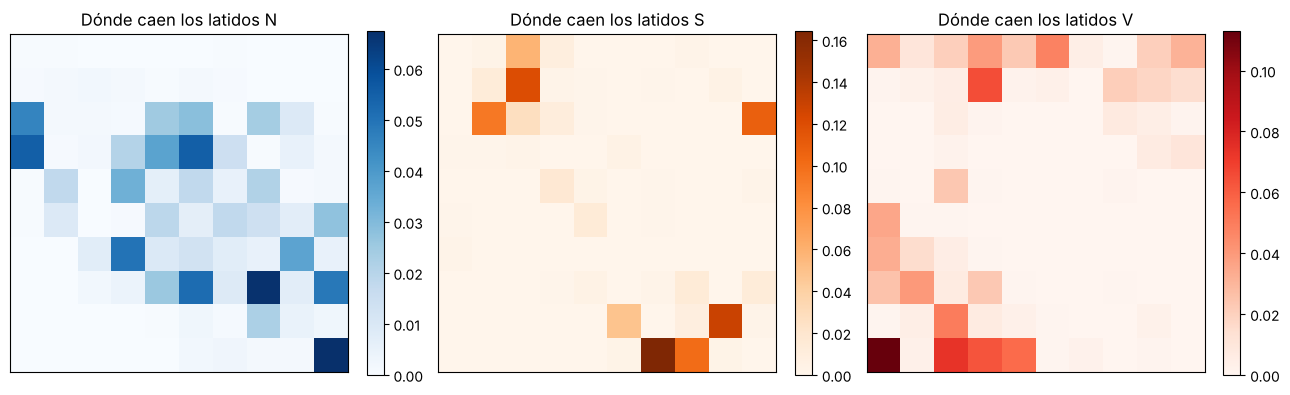

N: 1.2 % de sus latidos cae en neuronas donde manda otra clase
S: 41.0 % de sus latidos cae en neuronas donde manda otra clase
V: 11.4 % de sus latidos cae en neuronas donde manda otra clase


In [6]:
class SOM:
    def __init__(self, filas=10, cols=10, iters=30000, eta0=0.5, seed=0):
        self.f, self.c, self.T, self.eta0 = filas, cols, iters, eta0
        self.rng = np.random.default_rng(seed)
        self.pos = np.array([(i, j) for i in range(filas) for j in range(cols)], float)
    def fit(self, Z):
        self.W = Z[self.rng.choice(len(Z), self.f * self.c, replace=False)].copy()     # inicialización
        s0 = max(self.f, self.c) / 2
        for t in range(self.T):
            x = Z[self.rng.integers(len(Z))]
            g = np.argmin(((self.W - x) ** 2).sum(1))                                 # competición
            eta = self.eta0 * (0.01 / self.eta0) ** (t / self.T)
            sig = s0 * (0.5 / s0) ** (t / self.T)
            h = np.exp(-((self.pos - self.pos[g]) ** 2).sum(1) / (2 * sig ** 2))      # cooperación
            self.W += eta * h[:, None] * (x - self.W)                                 # adaptación
        return self
    def ganadora(self, Z):
        return np.argmin((Z**2).sum(1)[:, None] - 2 * Z @ self.W.T + (self.W**2).sum(1)[None, :], 1)

Zs, _ = entradas(X1n, F1n, a_rr=3.0)
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(y1 == 'N')[0], 6000, replace=False),
                      np.where(y1 == 'S')[0], np.where(y1 == 'V')[0]])
som = SOM().fit(Zs[idx])
g = som.ganadora(Zs)
H = np.array([[np.sum((g == n) & (y1 == k)) for k in CL] for n in range(100)])
mayoria = CL[np.argmax(H, 1)]

fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, k, cm in zip(axs, CL, ['Blues', 'Oranges', 'Reds']):
    im = ax.imshow((H[:, list(CL).index(k)] / np.sum(y1 == k)).reshape(10, 10), cmap=cm)
    ax.set_title(f'Dónde caen los latidos {k}'); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()
for k in CL:
    print(f'{k}: {100 * np.mean(mayoria[g[y1 == k]] != k):.1f} % de sus latidos cae en neuronas donde manda otra clase')

## 6. Selección de hiperparámetros: validación cruzada dejando un paciente fuera
Para cada uno de los 22 pacientes de DS1: se entrena con los otros 21 y se predice el que quedó fuera. Al final se juntan las predicciones de todos los pliegues y se calcula el F1. Tarda unos 5 a 8 minutos.

In [7]:
def cv_paciente(modelo, X, F, y, p, a_rr):
    yp = np.empty_like(y)
    for q in np.unique(p):
        te = p == q
        Ztr, ref = entradas(X[~te], F[~te], a_rr=a_rr)
        Zte, _ = entradas(X[te], F[te], ref, a_rr=a_rr)
        yp[te] = modelo().fit(Ztr, y[~te]).predict(Zte)
    return yp

filas = []
t0 = time.time()
m = metricas(y1, cv_paciente(Adaline, X1n, F1n, y1, p1, 1.0))
filas.append(dict(modelo='Adaline', k='-', f='-', F1_N=m['N']['F1'], F1_S=m['S']['F1'], F1_V=m['V']['F1'], F1_macro=m['macro']))
for k in [10, 25, 50]:
    for f in [1.0, 2.0, 4.0]:
        m = metricas(y1, cv_paciente(lambda: RBF(k, f), X1n, F1n, y1, p1, 3.0))
        filas.append(dict(modelo='RBF', k=k, f=f, F1_N=m['N']['F1'], F1_S=m['S']['F1'], F1_V=m['V']['F1'], F1_macro=m['macro']))
cv = pd.DataFrame(filas).round(3)
print(f'{time.time() - t0:.0f} s')
cv.sort_values('F1_macro', ascending=False)

297 s


,modelo,k,f,F1_N,F1_S,F1_V,F1_macro
8,RBF,50,2.0,0.937,0.324,0.552,0.604
4,RBF,25,1.0,0.939,0.271,0.577,0.595
7,RBF,50,1.0,0.938,0.235,0.571,0.582
9,RBF,50,4.0,0.924,0.307,0.443,0.558
5,RBF,25,2.0,0.926,0.286,0.441,0.551
6,RBF,25,4.0,0.920,0.292,0.416,0.543
1,RBF,10,1.0,0.917,0.211,0.437,0.522
2,RBF,10,2.0,0.909,0.196,0.415,0.506
3,RBF,10,4.0,0.914,0.151,0.446,0.504
0,Adaline,-,-,0.886,0.128,0.402,0.472


In [8]:
mejor = cv[cv.modelo == 'RBF'].sort_values('F1_macro', ascending=False).iloc[0]
K, FS_ = int(mejor.k), float(mejor.f)
print(f'Configuración elegida para la RBF: k = {K} centros por clase, f = {FS_}')

Configuración elegida para la RBF: k = 50 centros por clase, f = 2.0


## 7. Evaluación final en DS2 (una sola vez)
Se entrena con **todo** DS1 y se evalúa en los 22 pacientes de DS2, que nunca se usaron. La RBF se repite con 5 semillas de k-means para reportar media ± desviación.

In [9]:
Z1a, ref_a = entradas(X1n, F1n, a_rr=1.0); Z2a, _ = entradas(X2n, F2n, ref_a, a_rr=1.0)
Z1r, ref_r = entradas(X1n, F1n, a_rr=3.0); Z2r, _ = entradas(X2n, F2n, ref_r, a_rr=3.0)

yp_ada = Adaline().fit(Z1a, y1).predict(Z2a)
m_ada = metricas(y2, yp_ada)
m_rbf, yp_rbf = [], None
for s in range(5):
    yp = RBF(K, FS_, seed=s).fit(Z1r, y1).predict(Z2r)
    m_rbf.append(metricas(y2, yp)); yp_rbf = yp if s == 0 else yp_rbf

def fila(nombre, ms):
    ms = ms if isinstance(ms, list) else [ms]
    r = {'modelo': nombre}
    for k in CL:
        r[f'{k} Se %'] = 100 * np.mean([x[k]['Se'] for x in ms]); r[f'{k} PP %'] = 100 * np.mean([x[k]['PP'] for x in ms])
    r['F1 macro'] = np.mean([x['macro'] for x in ms]); r['± (semillas)'] = np.std([x['macro'] for x in ms])
    return r

tabla = pd.DataFrame([fila('Adaline (pseudoinversa)', m_ada), fila(f'RBF (k={K}, f={FS_})', m_rbf)]).round(3)
tabla.loc[len(tabla)] = {'modelo': 'de Chazal 2004 (referencia)', 'S Se %': 75.9, 'S PP %': 38.5, 'V Se %': 77.7, 'V PP %': 81.9}
tabla

,modelo,N Se %,N PP %,S Se %,S PP %,V Se %,V PP %,F1 macro,± (semillas)
0,Adaline (pseudoinversa),90.956,99.054,76.688,35.484,92.606,63.399,0.729,0.000
1,"RBF (k=50, f=2.0)",91.804,99.105,52.571,29.979,84.442,53.408,0.663,0.011
2,de Chazal 2004 (referencia),NaN,NaN,75.900,38.500,77.700,81.900,NaN,NaN


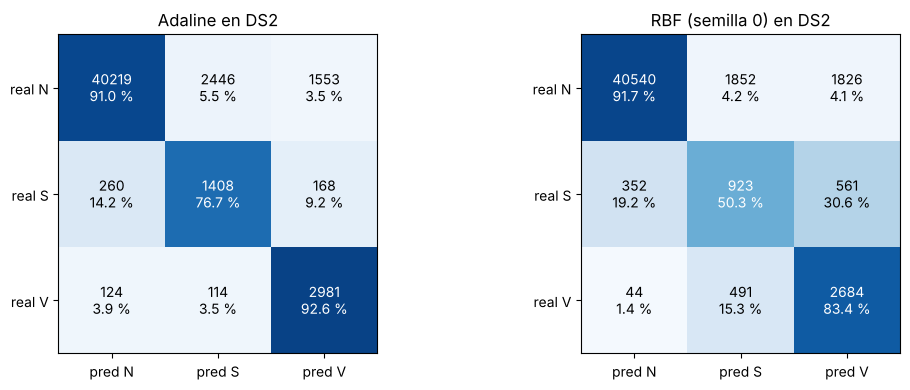

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nombre, yp) in zip(axs, [('Adaline', yp_ada), ('RBF (semilla 0)', yp_rbf)]):
    M = matriz_confusion(y2, yp).values
    ax.imshow(M / M.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{M[i, j]}\n{100 * M[i, j] / M[i].sum():.1f} %', ha='center', va='center',
                    color='white' if M[i, j] / M[i].sum() > .5 else 'black')
    ax.set_xticks(range(3), [f'pred {k}' for k in CL]); ax.set_yticks(range(3), [f'real {k}' for k in CL])
    ax.set_title(f'{nombre} en DS2')
plt.tight_layout(); plt.show()

## 8. Conclusiones para el informe de la entrega 1

1. **El problema no es linealmente separable.** El SOM muestra que más del 40 % de los latidos S cae en neuronas dominadas por otra clase, y el Adaline, con todo y la ponderación, acierta solo cerca de un tercio de las veces que predice "S".
2. **El pipeline está bien.** El Adaline en DS2 obtiene en la clase S una sensibilidad y una predictividad positiva muy parecidas a las del clasificador lineal de de Chazal (2004).
3. **La RBF gana en validación pero pierde en DS2.** En la validación cruzada sobre DS1 supera al Adaline, pero en los pacientes nuevos de DS2 queda por debajo. Sus neuronas gaussianas son locales: se ubican sobre grupos de latidos de pacientes concretos y no generalizan a morfologías que no vio. Es el problema central de la evaluación inter-paciente.
4. **Implicación para la entrega 2:** hace falta un modelo no lineal que aprenda rasgos que no dependan del paciente (la CNN 1D, cuyas convoluciones detectan formas sin importar su posición exacta), con regularización (weight decay, dropout) para no memorizar a los pacientes de entrenamiento.

*Nota de método:* DS2 se usó una sola vez, después de fijar todo con DS1. Reajustar la RBF mirando estos resultados invalidaría la comparación.